# Time Series Analysis of Apple Stock Prices from 2016 to 2026

Introduction etc...

## Preparation of the dataset

In [3]:
import warnings
warnings.filterwarnings('ignore')
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm  

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  
# plot_acf: plots autocorrelation function (used to identify MA terms)
# plot_pacf: plots partial autocorrelation function (used to identify AR terms)

plt.style.use('fivethirtyeight')
from pylab import rcParams
rcParams['figure.figsize'] = 10, 6
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima_model import ARIMA
from pmdarima.arima import auto_arima
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

In [4]:
# plotds is method to plot time series, ACF and PACF
def plotds(xt, nlag = 30, fig_size = (12, 10)):            # Function to plot time series, ACF, and PACF
    if not isinstance(xt, pd.Series):                      # Check if input is not a pandas Series
         xt = pd.Series(xt)                                # Convert input to pandas Series if needed
         
    plt.figure(figsize = fig_size)                         # Create a figure with specified size
    layout = (2, 2)                                        # Define grid layout (2 rows x 2 columns)
    
    ax_xt = plt.subplot2grid(layout, (0, 0), colspan = 2)  # Top plot spans both columns (time series)
    ax_acf= plt.subplot2grid(layout, (1, 0))               # Bottom-left plot for ACF
    ax_pacf = plt.subplot2grid(layout, (1, 1))             # Bottom-right plot for PACF
    
    xt.plot(ax = ax_xt)                                    # Plot the time series data
    ax_xt.set_title('Time Series')                         # Set title for time series plot
    
    plot_acf(xt, lags = 50, ax = ax_acf)                   # Plot autocorrelation function (ACF)
    plot_pacf(xt, lags = 50, ax = ax_pacf)                 # Plot partial autocorrelation function (PACF)
    
    plt.tight_layout()                                     # Adjust layout to prevent overlapping
    return None                                            # Function returns nothing

### Data Import and Preprocessing

In [6]:
import os # OS library has functions that help with file operations
os.getcwd() #get the path of current working directory
#os.chdir("C:/Users/Sugandha Arora/Desktop/DataScienceInstitue/CCT/Datasets")

'C:\\Users\\sonas\\ML second semester materials'

In [7]:
#Import the dataset
data = pd.read_excel('AAPL_data.xlsx')
data.head()

,Date,Close,High,Low,Open,Volume
0,2025-10-10,244.367325,255.436437,243.101995,254.001734,61999100
1,2025-10-13,246.748520,248.771048,244.656243,248.462191,38142900
2,2025-10-14,246.858109,247.934135,243.799400,245.692416,35478000
3,2025-10-15,248.422333,250.893216,246.559220,248.571790,33893600
4,2025-10-16,246.539276,248.123421,244.227823,247.336335,39777000


In [8]:
data['Date'] = pd.to_datetime(data.Date,format='%Y-%m-%d')

In [9]:
#Reverse the order of the dataset so that the latest year data will arrive in the tail of the dataframe
data = data.iloc[::-1]

In [10]:
#View the dataset
data.head(20)

,Date,Close,High,Low,Open,Volume
250,2026-10-09,336.640015,338.609985,330.700012,331.700012,37855000
249,2026-10-08,340.420013,341.570007,335.899994,336.820007,35332400
248,2026-10-07,336.670013,338.670013,332.779999,336.959991,34147900
247,2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000
246,2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900
245,2026-10-02,333.690002,334.540009,330.609985,333.260010,33278600
244,2026-10-01,330.320007,332.480011,325.809998,330.000000,36306300
243,2026-09-30,333.019989,339.500000,330.140015,330.799988,49988600
242,2026-09-29,329.399994,337.089996,328.700012,336.970001,38478000
241,2026-09-28,338.399994,342.989990,338.040009,340.369995,32820800


In [11]:
data.isnull().sum()

Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

In [12]:
data.dtypes

Date      datetime64[ns]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
dtype: object

In [13]:
data.duplicated().sum()

np.int64(0)

 From the overview above, we can see that the data is clean and does not need any serious cleaning. There are no missing values or any duplicate. Let us move forward

In [14]:
#Use date column as the index
data.reset_index(inplace=True)

In [15]:
data.head()

,index,Date,Close,High,Low,Open,Volume
0,250,2026-10-09,336.640015,338.609985,330.700012,331.700012,37855000
1,249,2026-10-08,340.420013,341.570007,335.899994,336.820007,35332400
2,248,2026-10-07,336.670013,338.670013,332.779999,336.959991,34147900
3,247,2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000
4,246,2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900


# Exploratory — Trends, Seasonality and Anomalies

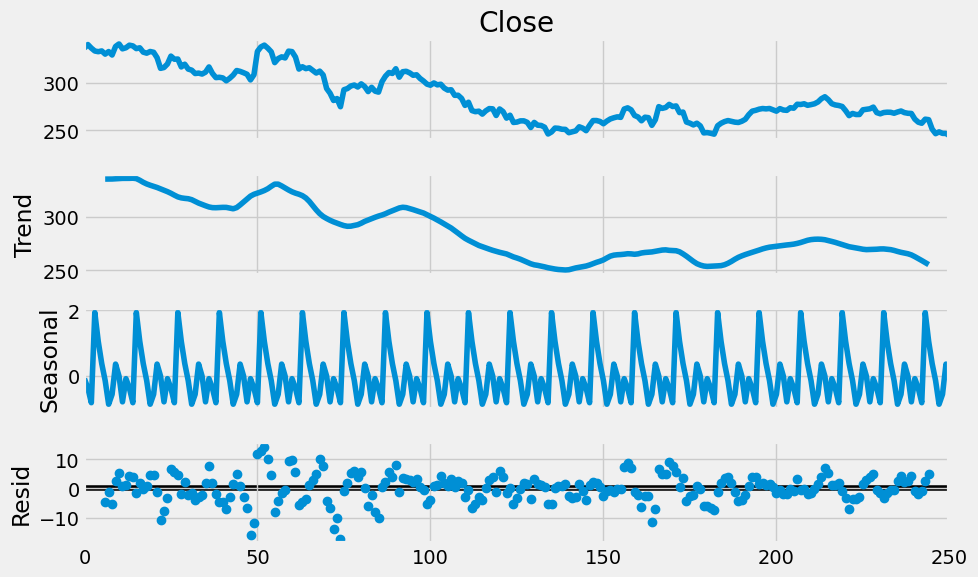

In [16]:
#data['Date'] = pd.to_datetime(data['Date'])
#data = data.set_index('Date')

s = data['Close']

decomp = sm.tsa.seasonal_decompose(
    s.interpolate(),
    model='additive',
    period=12
)

decomp.plot()
plt.show()

We examined the trend, seasonal and residual components by appling additive time series decomposition to Apple's closing prices. The seasonal period of 12 observations to investigate possible repeated patterns.  From it, is possible to notice: 

Close: Stock prices don't stay the same and fluctuate over time.

Trend: The Trend component suggests a predominantly downward trend in the period analyzed. 

Seasonal: The decomposition identified a periodic pattern in the data. 

Resid: The series contains variations that aren't completely explained by the Trend and Seasonal components. Also, the residuals don't seem to be distributed completely randomly around zero, which could indicate patterns that haven't been captured yet.

### Visualization of the evolution of stock prices

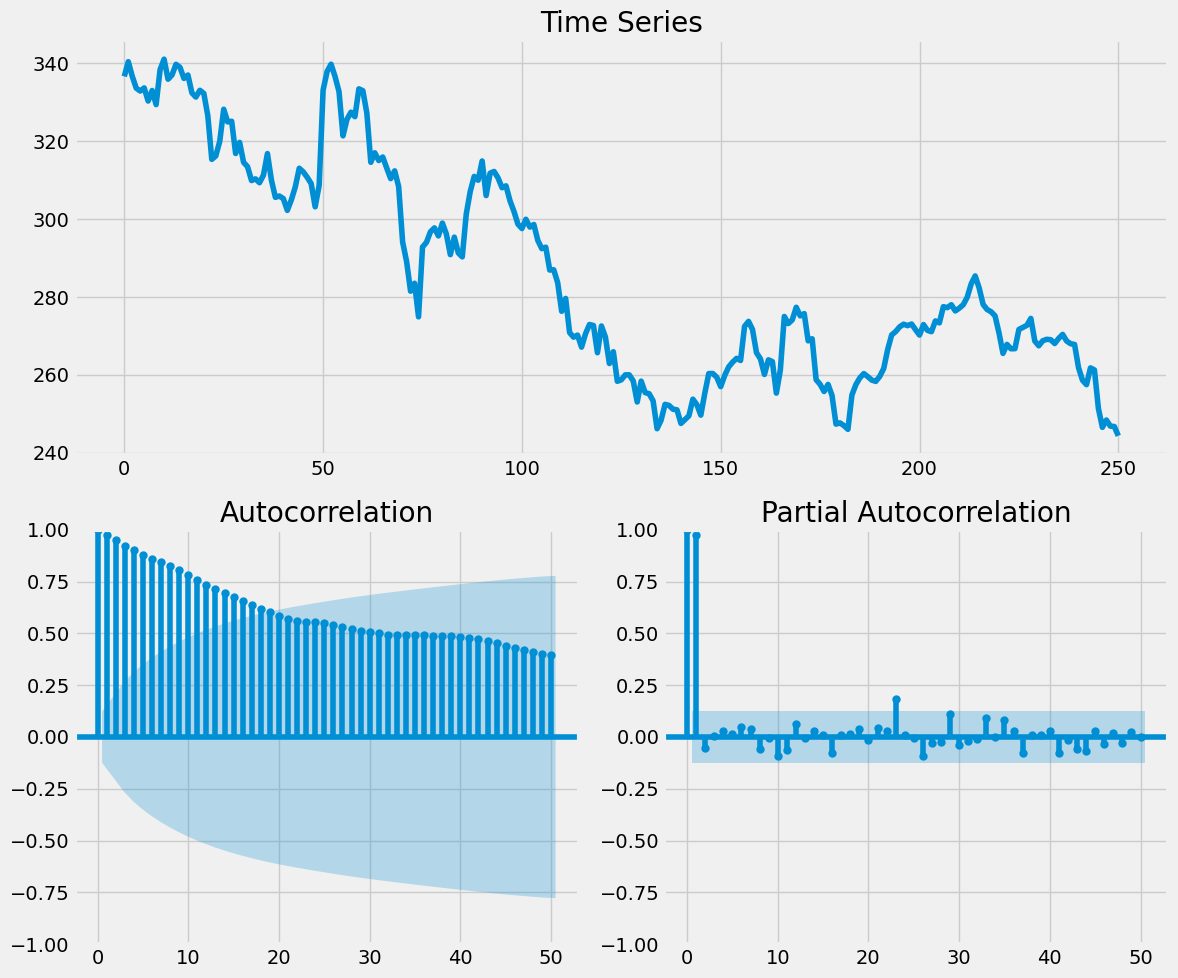

In [17]:
# Display plot of close column and Date index
plotds(data['Close'], nlag = 100)

### Discuss what insights you can derive from the initial exploration of the time series data. Describe any trends, seasonality, or anomalies observed.

We selected the closing price (Close) as the main variable to analyse time series patterns and forecast future stock prices. The initial exploration of Apple's closing stock prices showed a general downward trend over the period analysed, with several fluctuations and rapid price changes. We do not notice clear seasonal pattern. The Autocorrelation Function (ACF) showed a positive autocorrelation that decreased slowly across the lags. This suggests that the original time series may be is non-stationary. 

In addition, the Partial Autocorrelation Function (PACF) showed a strong spike at the first lag, indicating a strong relationship between consecutive observations.These findings were consistent with the Augmented Dickey-Fuller (ADF) test, which generated a p-value of 0.5359. Therefore, first-order differencing was applied to improve stationarity before selecting the ARIMA parameters. Also it showed differences in the mean and variance between the two parts of the time series. The mean decreased from 308.37 to 263.80, while the variance decreased from 445.26 to 98.11. These differences suggest that the statistical properties of the series changed over time.The Q-Q plot showed deviations from the theoretical normal distribution, suggesting that the closing prices were not normally distributed.Furthermore, the Augmented Dickey-Fuller (ADF) test produced a statistic of -1.4952 and a p-value of 0.5359. Since the p-value was greater than 0.05, the null hypothesis of a unit root could not be rejected. This result suggested that the original time series was non-stationary. After applying first-order differencing, the ADF test produced a p-value below 0.05, providing evidence of stationarity. Therefore, the differencing parameter was set to d=1 for the ARIMA model.

### Identify ARIMA parameters (p, d, q)

## ACF plot
* The ACF starts near 1.0 at lag 0 (always true). Then slowly decreases (decays) as lag increases. It stays positive for many lags. This shows that 
- Your data has strong persistence / memory
- Values are highly related to past values even far back
- This pattern is typical Non-stationary data, or A strong trend, or An AR (autoregressive) process
- If lag = 100, it means you are analyzing up to 100 past steps
- ACF (left plot): shows total correlation (direct + indirect)
- PACF (right plot): shows only direct correlation
## PACF plot
* PACF has a strong spike at lag 1, then drops down which suggests an AR(1) process.
* PACF measures the direct relationship between a time series and its lagged values, after removing the effects of intermediate lags.
* Only lag 1 is significant while the higher lags contribute no direct information
* This strongly suggests the series behaves like an AR(1) (AutoRegressive order 1) process

In [18]:
# Calculate the mean value of first 125 rows and afterwards
mean1, mean2 = data.iloc[:125].Close.mean(), data.iloc[125:].Close.mean()

# Calculate the variance value of first 125 rows and afterwards
var1, var2 = data.iloc[:125].Close.var(), data.iloc[125:].Close.var()

# Display mean and variance of two parts of the time series
print('mean1 = %f, mean2 = %f' % (mean1, mean2))
print('variance1 = %f, variance2 = %f' % (var1, var2))

mean1 = 308.371073, mean2 = 263.796183
variance1 = 445.259287, variance2 = 98.110587


### Stationarity Test

In [20]:
from statsmodels.tsa.stattools import adfuller

# Call adfuller() function to calculate the values
adf_result = adfuller(data.Close.tolist())
print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

ADF Statistic: -1.495235
p-value: 0.535867


### ADF statistic of -1.4952 and a p-value of 0.535867, suggesting that the series is non-stationary.

### ACF and PACF visualization 

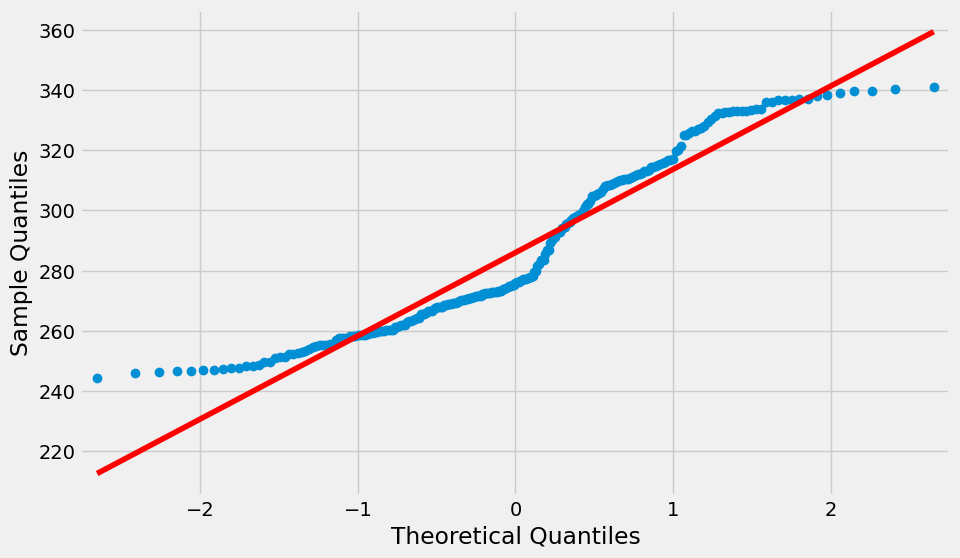

In [21]:
# qqplot for the 'Close' column
x = sm.qqplot(data['Close'], line = 's')

# Model Fitting
## Moving Average

### How the model represents the observed data

## ARIMA

In [22]:
from statsmodels.tsa.arima.model import ARIMA

# Call ARIMA function to train the model on the 'Close' price
model = ARIMA(data['Close'], order = (1, 1, 0))

# Train ARIMA Model on the 'Close' price dataset
results_AR = model.fit()

In [23]:
# Store one difference value of the 'Close' column
first_order_diff = data['Close'].diff(1)

# Display the first five records
first_order_diff.head()

0         NaN
1    3.779999
2   -3.750000
3   -3.040009
4   -0.739990
Name: Close, dtype: float64

In [24]:
# Drop the first row of 'Close' column because It has 'NaN' value
first_order_diff = data['Close'].diff(1).dropna()

# Display the first five records
first_order_diff.head()

1    3.779999
2   -3.750000
3   -3.040009
4   -0.739990
5    0.799988
Name: Close, dtype: float64

Text(0.5, 1.0, 'First-order differences of APPLE')

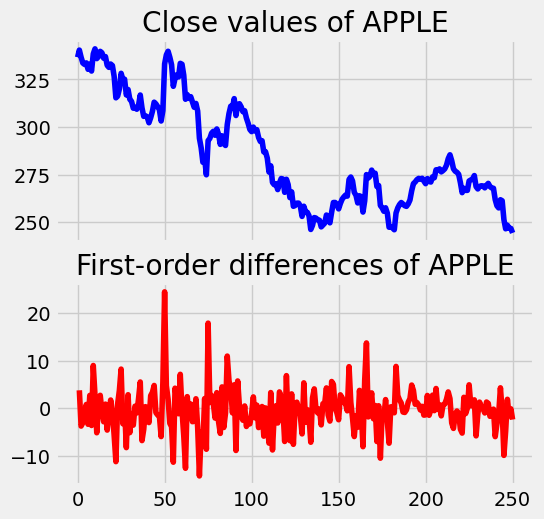

In [27]:
# Declare the fig abd ax as two arguments 
fig, ax = plt.subplots(2, sharex = True)
fig.set_size_inches(5.5, 5.5)
data['Close'].plot(ax = ax[0], color = 'b')
ax[0].set_title('Close values of APPLE')
first_order_diff.plot(ax = ax[1], color = 'r')
ax[1].set_title('First-order differences of APPLE')

The first chart shows the original prices, wich present an overall downward trend. The second one shows the differences between consecutive prices. These differences appear to fluctuate around zero. We used these charts to check whether the time series became stationary after first-order differencing, which is important for ARIMA modelling.

In [39]:
# A nested loop is written to calculate the AIC values
aicVal = []                                      # Initialize an empty list to store ARIMA parameters and AIC values

for d in range(1, 3):                             # Loop over differencing order (d = 1 to 2)
    for ari in range(0, 3):                       # Loop over AR terms (p = 0 to 2)
        for maj in range(0, 3):                   # Loop over MA terms (q = 0 to 2)
            try:
                arima_obj = ARIMA(data['Close'].tolist(), order=(ari, d, maj))  # Create ARIMA model with parameters (p=ari, d=d, q=maj)                
                arima_obj_fit = arima_obj.fit()                                    # Fit the ARIMA model to the data                
                aicVal.append([ari, d, maj, float(arima_obj_fit.aic)])             # Store p, d, q values along with the computed AIC
            except ValueError:                                                     # Handle cases where model fails to fit
                pass                                                               # Ignore errors and continue loop

# Print results line by line
for val in aicVal:                                                                 # Loop through stored AIC results
    print(val)                                                                     # Print each combination of (p, d, q) and its AIC value


[0, 1, 0, 1461.822286374123]
[0, 1, 1, 1463.1166618946722]
[0, 1, 2, 1465.0822586832228]
[1, 1, 0, 1463.1052137364184]
[1, 1, 1, 1465.1026851594702]
[1, 1, 2, 1467.0411379512425]
[2, 1, 0, 1465.099048098621]
[2, 1, 1, 1467.0532675707595]
[2, 1, 2, 1461.5522018330007]
[0, 2, 0, 1615.3573216657676]
[0, 2, 1, 1462.8136549116857]
[0, 2, 2, 1464.1714852035154]
[1, 2, 0, 1553.9682430400503]
[1, 2, 1, 1464.1636028695716]
[1, 2, 2, 1465.350305615146]
[2, 2, 0, 1533.5952210535538]
[2, 2, 1, 1466.1614114318907]
[2, 2, 2, 1467.1003895569484]


We tested 18 models  of ARIMA parameters (p, d, q) and compared using the AIC, than according to the AIC ARIMA (2,1,2) is the best because produced the lowest AIC value of 1461.55. However, ARIMA(0,1,0) produced a similar AIC value of 1461.82.

In [34]:
# Find the minimum AIC value and corresponding model
best_model = min(aicVal, key=lambda x: x[3])
print(f"\nMinimum AIC value: {best_model[3]:.2f}")
print(f"Best model: ARIMA({best_model[0]}, {best_model[1]}, {best_model[2]})")


Minimum AIC value: 1461.55
Best model: ARIMA(2, 1, 2)


AIC: Akaikes Information Criterion: Estimator of the relative quality of statistical models for a given set of data. The AIC deals with the trade-off betwen the goodness of fit of the model and the simplicity of the model.

## ARIMA(2,1,2) Model Results and Residual Diagnostics

In [36]:
# Declare and initialise an object 'arima_obj' by calling a method 'ARIMA()'
arima_obj = ARIMA(data['Close'].tolist(), order = (2, 1, 2))

# d = 2, the number of times that the raw observations are differenced, also called the degree of differencing.

# Train the ARIMA model by calling a method fit()
arima_obj_fit = arima_obj.fit()

# disp : int, optional
# If True, convergence information is printed.  For the default l_bfgs_b solver, disp controls the frequency of the output 
# during the iterations. disp < 0 means no output in this case.

# Display the summary of the trained model
arima_obj_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  251
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -725.776
Date:                Tue, 13 Oct 2026   AIC                           1461.552
Time:                        10:42:12   BIC                           1479.160
Sample:                             0   HQIC                          1468.639
                                - 251                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.4474      0.031     46.859      0.000       1.387       1.508
ar.L2         -0.9756      0.031    -31.895      0.000      -1.036      -0.916
ma.L1         -1.4160      0.050    -28.369      0.000      -1.514      -1.318
ma.L2          0.9345      0.051     18.418      0.000       0.835       1.034
sigma2        19.4213      1.171     16.579      0.000      17.125      21.717
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):               174.39
Prob(Q):                              0.88   Prob(JB):                         0.00
Heteroskedasticity (H):               0.34   Skew:                             0.67
Prob(H) (two-sided):                  0.00   Kurtosis:                         6.86
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

The ARIMA(2,1,2) model was fitted using 251 observations and achieved an AIC value of 1461.55. The Ljung–Box test produced a p-value of 0.88, indicating no significant residual autocorrelation at lag 1. However, the Jarque–Bera of  p-value= 0.00, showing a p-value below 0.05, suggesting that the residuals were not normally distributed. In addition, the heteroskedasticity test indicated that the variance of the residuals was not constant. These results suggest that the model captured some important patterns in the data, but limitations remained in the residual distribution and variance. We will address it during the evaluation of the performance of the ARIMA/SARIMA model in forecasting future values.

## Comparison of Actual Apple Stock Prices and ARIMA Model Estimates

In [56]:
# Declare the array 'pred' and append the values 
pred = arima_obj_fit.fittedvalues

# Add a new column 'ARIMA' into dataframe
data['ARIMA'] = pred

# Residues and fitted values are added and stored into dataframe
diffval = arima_obj_fit.resid + arima_obj_fit.fittedvalues

# Add a column 'diffval' into dataframe
data['diffval'] = diffval

# Display first five records
data.head()

,index,Date,Close,High,Low,Open,Volume,ARIMA,diffval
0,250,2026-10-09,336.640015,338.609985,330.700012,331.700012,37855000,0.000000,336.640015
1,249,2026-10-08,340.420013,341.570007,335.899994,336.820007,35332400,336.640384,340.420013
2,248,2026-10-07,336.670013,338.670013,332.779999,336.959991,34147900,340.626548,336.670013
3,247,2026-10-06,333.630005,334.380005,330.619995,332.279999,30449000,336.477241,333.630005
4,246,2026-10-05,332.890015,336.209991,331.649994,332.820007,34400900,333.272102,332.890015


This table  compares the actual closing prices of Apple shares with the fitted values obtained from the ARIMA model. The results show differences between the observed prices and the values estimated by the model. For example, on 8 October 2026, the actual closing price was approximately $340.42, while the fitted value was $336.64. These results help to assess how well the ARIMA model fits the historical data. 

#Atention order decrecente...

# ARIMA parameters (p, d, q)

### Q-Q Plot of ARIMA(2,1,2) Model Residuals

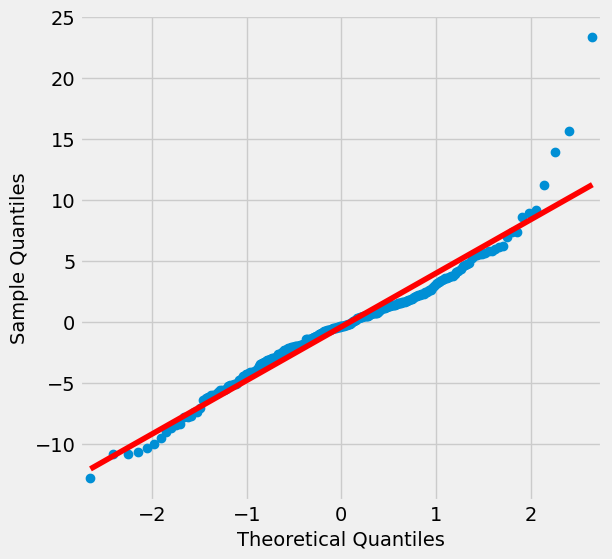

In [57]:
# Q-Q plot of the quantiles of x versus the quantiles/ppf of a distribution.
# Call qqplot() for arima_obj_fit
fig, ax = plt.subplots(figsize=(6, 6))

# Remove the first and last point from residuals
residuals = arima_obj_fit.resid[2:]

sm.qqplot(residuals, line='s', ax=ax)
plt.show()

We used the Q-Q plot  to assess the normality of the ARIMA(2,1,2) model residuals. Most points in the central part of the plot are close to the reference line, suggesting an approximately normal distribution in this region. However, some points in the upper right tail deviate considerably from the line, indicating extreme positive residuals and departures from normality. This finding is consistent with the Jarque–Bera test of p-value = 0.00 it is p-value < 0.05, which indicates that the residuals are not normally distributed.

## Comparison of Actual Apple Stock Closing Prices and ARIMA(2,1,2) Fitted Values

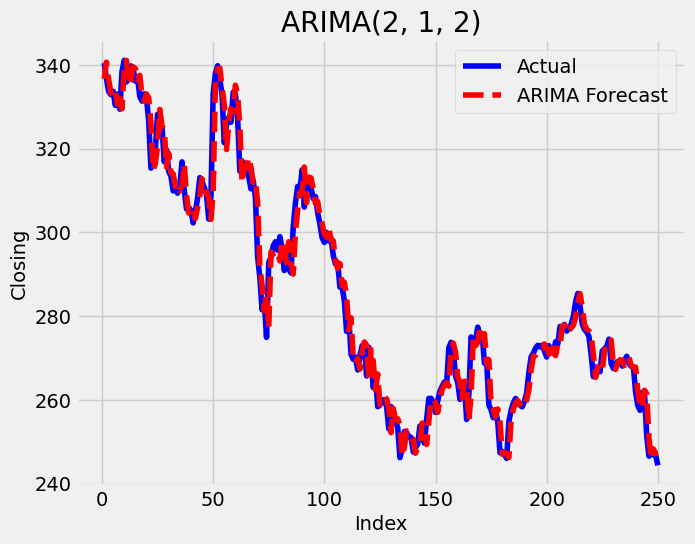

In [61]:
# Declare the objects f and array axarr
f, axarr = plt.subplots(1, sharex=True)
f.set_size_inches(7, 5.5)

# Ignore first two rows because of difference factor d = 1
data['diffval'].iloc[1:].plot(color='b', linestyle='-', ax=axarr, label='Actual')
data['ARIMA'].iloc[1:].plot(color='r', linestyle='--', ax=axarr, label='ARIMA Forecast')
axarr.set_title('ARIMA(2, 1, 2)')
axarr.set_xlabel('Index')
axarr.set_ylabel('Closing')
axarr.legend()  # Add legend

plt.show()

In [62]:
from sklearn.metrics import r2_score

# Drop NaNs and align properly
actual = data['diffval'].iloc[2:]
predicted = data['ARIMA'].iloc[2:]

# Ensure same length (important!)
actual, predicted = actual.align(predicted, join='inner')

r2 = r2_score(actual, predicted)
print(f"R² Score: {r2:.4f}")

R² Score: 0.9740


The graph compares the actual Apple stock closing prices with the fitted values obtained from the ARIMA(2,1,2) model. It suggests a good fit to the historical data as we can notice by the red line that follows the blue line, indicating that the model captures many of the historical price movements. However, in some moment the red line doesn't perfectly follow the blue one indicating model fitting errors. At the beginning of the chart, prices are around $340. By the end, they're close to $250 (ups and downs throughout the period without necessarily representing the entire ten-year period.)

# SARIMA

#### Parameter estimcation for SARIMA

In [42]:
#import pmdarima as pm
#model = pm.auto_arima(s, max_p=2, max_q=2,max_P=2,max_Q=2,d=1,m=12,seasonal=True,D=1, suppress_warnings=True,trace=True)
#model

##### CAN BE DELETED We are using auto ARIMA function to get parameters for SARIMA. 

auto_arima() generates the best order arima model. The function conducts a search over possible model within the order constraints provided.
trace= True returns the list of all models considered.
max_p and max_q gives maximum values of p and q respectively.
seasonal= allows to specify whether to fit a seasonal ARIMA or not.

## SARIMA Model Results and Residual Diagnostics

In [41]:
# order = (2, 1, 2) means
# First 2 for auto regressive model, 1 for difference, and second 2 for moving average
# seasonal_order = (2, 1, 2, 12) means
# 12 additional parameter means number of observations per year or the period
best_model = SARIMAX(data['Close'], order = (2, 1, 2), seasonal_order = (2, 1, 2, 12)).fit(dis = -1)

# Display the summary of the model
print(best_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                  251
Model:             SARIMAX(2, 1, 2)x(2, 1, 2, 12)   Log Likelihood                -708.135
Date:                            Tue, 13 Oct 2026   AIC                           1434.269
Time:                                    10:59:10   BIC                           1465.520
Sample:                                         0   HQIC                          1446.864
                                            - 251                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.4418      0.039     37.082      0.000       1.366       1.518
ar.L2         -0.9722      0.037   

#### Explanation
We used (0,1,0)(2,1,0,12) parameters and we added the value 12 as in the SARIMA (0,1,0)(2,1,0,12) to investigate a possible annual seasonal pattern in monthly observations. This model is similar to ARIMA models, but we add a few parameters to include for the seasons. (Reference Lecture 6). 

The model obtained an AIC value of 1434.27, compared with ARIMA(2,1,2) model value of 1461.55. 

The Ljung–Box test produced a p-value of 0.97, indicating no significant residual autocorrelation at lag 1. 

However, the Jarque–Bera test (p-value < 0.05) indicated that the residuals were not normally distributed. The heteroskedasticity test also suggested that the residual variance was not constant. 

Although SARIMA shows a lower AIC, there are still limitations in the residuals and in the estimation of the seasonal component.

## Summary of SARIMA Model Residual Diagnostics

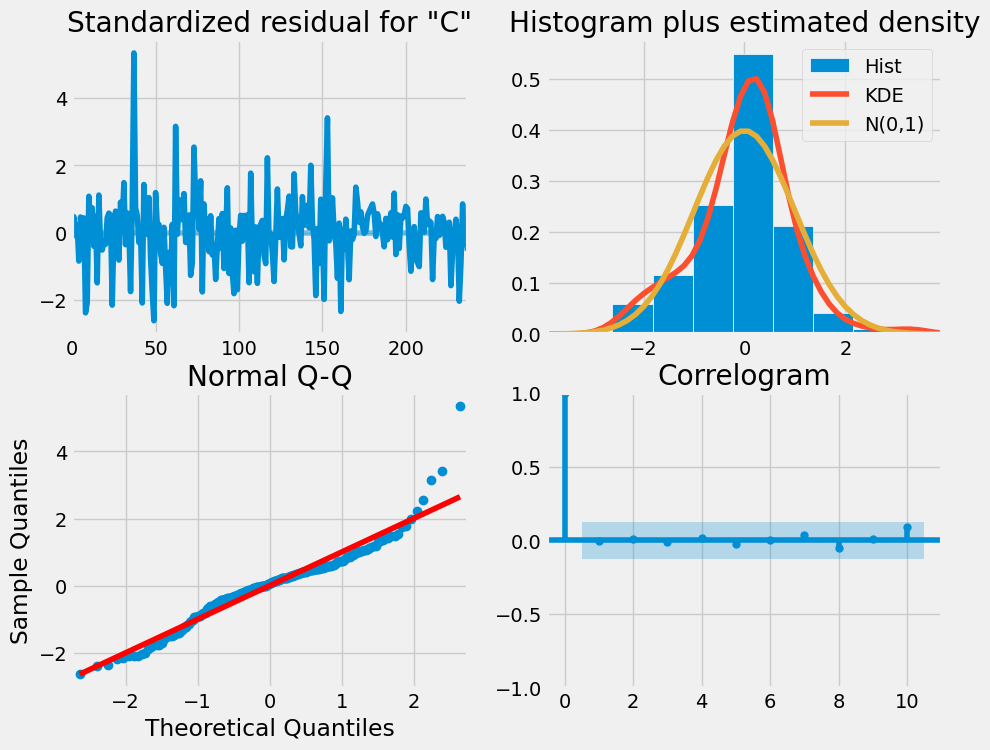

In [46]:
# Diagnosing the model residuals
best_model.plot_diagnostics(figsize = (10, 8))
plt.show()

We are presented this graph to help assess the statistical quality of the model by the residual diagnostics of the SARIMA model. 

We observe that the standardized residuals fluctuate around zero, although some large variations can be observed. 

The histogram and Q-Q plot indicate deviations from a normal distribution, particularly in the upper tail.

The correlogram shows that most residual autocorrelations are close to zero and within the confidence limits, suggesting limited evidence of remaining autocorrelation. 

This is consistent with the Ljung–Box test (p-value = 0.97 at lag 1). 

## Model Forecast

### How the model predicts future data that wasn't used in training

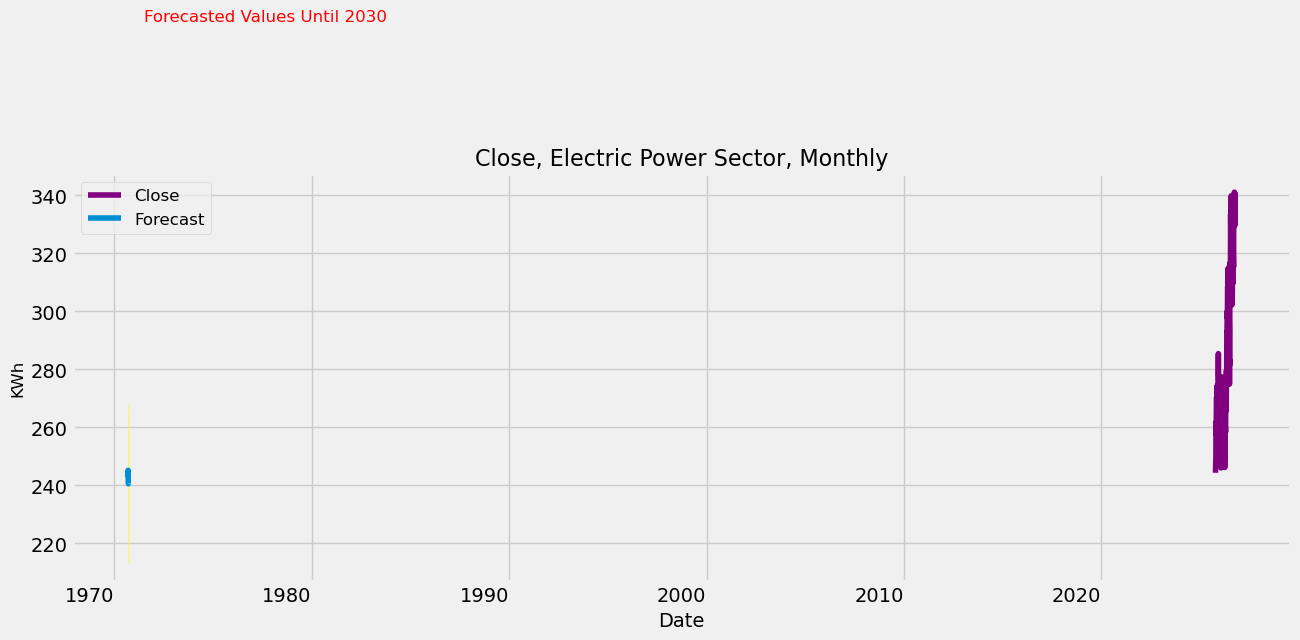

In [65]:
# Forecasting 3 years steps ahead
forecast_values = best_model.get_forecast(steps = 10)

# Confidence intervals of the forecasted values
forecast_ci = forecast_values.conf_int()

# Plot the data
ax = data.plot(x = 'Date', y = 'Close', figsize = (14, 6), legend = True, color = 'purple')

# Plot the forecasted values 
forecast_values.predicted_mean.plot(ax = ax, label = 'Forecast', figsize = (14, 6), grid = True)

# Plot the confidence intervals
ax.fill_between(forecast_ci.index,
                forecast_ci.iloc[: , 0],
                forecast_ci.iloc[: , 1], color = 'yellow', alpha = .5) # alpha controls the transparency (opacity) of the shaded area.
plt.title('Close, Electric Power Sector, Monthly', size = 16)
plt.ylabel('KWh', size = 12)
plt.legend(loc = 'upper left', prop = {'size': 12})
ax.axes.get_xaxis().set_visible(True)
# annotation
ax.text(540, 400, 'Forecasted Values Until 2030', fontsize = 12,  color = 'red')
plt.show()